# Plot simulation results

Python translation of `plot_sim_results.Rmd`: coverage and Type I error of the standard error
methods against the number of points, from the summary written by
`server_jobs/array_job/combine_and_summarize.py`. Figures are saved to `figures/` next to this
notebook (the R version saves them next to the Rmd, so the two do not overwrite each other).

In [1]:
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import FuncFormatter, MaxNLocator, NullFormatter

import rfcorr as rc

plt.rcParams.update({"font.size": 12})
fig_dir = "figures"
os.makedirs(fig_dir, exist_ok=True)

## Read and prepare the summary

In [2]:
# server job array run (see server_jobs/array_job/combine_and_summarize.py)
# sim_name is only used to name the saved figures here
sim_name = "2d_expanse_m1000"
file = "../server_jobs/array_job/sim_summary.xlsx"

sim_all_raw = pd.read_excel(file)

sim_all = sim_all_raw.copy()
# legend names for the lag rules ('optimal_rate' is the current name of 'auto')
sim_all["M_method_plot"] = sim_all["M"].replace(
    {"cubic_root": "n^0.3", "linear": "0.2n", "auto": "n^(d/d+2)", "optimal_rate": "n^(d/d+2)"})
sim_all["constant_fct"] = sim_all["constant"].astype(str)
# squared Gaussian fields are chi^2_1 fields
is_chisq1 = (sim_all["distribution"] == "gaussian") & (sim_all["trans"] == "square")
sim_all["distribution"] = sim_all["distribution"].where(~is_chisq1, "chisq1")
# earlier method codes mapped to the current ones
sim_all["method"] = sim_all["method"].replace(dict(rc.get_defaults()["se_method_aliases"]))
# legend order as in the paper; any other method codes follow these
paper_order = ["general", "gauss", "indep", "iid"]
present = set(sim_all["method"])
method_order = [m for m in paper_order if m in present] + sorted(present - set(paper_order))

# number of observed points: n_obs is recorded for runs with a mask; older runs use the full grid
if "n_obs" not in sim_all:
    sim_all["n_obs"] = np.nan
sim_all["n_obs"] = sim_all["n_obs"].fillna(sim_all["nx"] ** sim_all["n_dim"])
# a missing dep_model (or no dep_model column) means X and Y depend only through rho
if "dep_model" not in sim_all:
    sim_all["dep_model"] = np.nan
sim_all["dep_model"] = sim_all["dep_model"].fillna("none")
# rows with the paper's lag rule, under its current or earlier name
sim_all["paper_rule"] = sim_all["M"].isin(["optimal_rate", "auto"])

# x axis for plots against the number of points, on a log scale since n_obs grows like nx^d
x_lab_n = "Number of points (N)"

In [3]:
# number of replications per setting, from the m_sim column of the results
n_sim = sim_all["m_sim"].unique()
if len(n_sim) != 1:
    raise ValueError(f"settings use different m_sim values: {', '.join(map(str, n_sim))}")
n_sim = int(n_sim[0])
alpha = 0.05
se = np.sqrt(alpha * (1 - alpha) / n_sim)

## Plotting function

`plot_by_method` plots a summary measure against the number of points, one colour per method.
Panels are a grid (`rows` by `cols`, either can be `None`) or, with `wrap`, one panel per value of
that column, `ncol` per row. Options as in the R version:

- `y`, `target`, `ylab`: e.g. `y="power"`, `target=alpha`, `ylab="Type I error rate"` for the Type I error
- `method_labels`: dict mapping method codes to legend names, e.g. `labels_ci` below
- `linetype`: optional column for line types, e.g. `"M_method_plot"` to compare bandwidths, with `linetype_name` as its legend title
- `caption`: `True` shows the dimension, distribution and dependence design in the data; a string is used as the caption
- `distribution`, `dep_model`: optional subsets, e.g. `"gaussian"`, `["gaussian", "chisq1"]`, or `"none"` for rows without a design; `None` keeps all

In [4]:
# legend names matching the method names in the paper:
# labels_ci for confidence intervals (coverage), labels_test for tests (Type I error, power)
labels_ci = {"general": "RFCorr", "gauss": "RFCorr-Gauss", "indep": "RFCorr-Indep", "iid": "naive"}
labels_test = {"general": "RFCorr-0", "gauss": "RFCorr-Gauss-0", "indep": "RFCorr-Indep",
               "iid": "naive"}
# colour of each method in every figure, the first four d3 colours (ggsci::pal_d3) in the paper's
# method order, so the naive method (iid) is always red even when another method is left out
method_colors = dict(zip(paper_order, ["#1F77B4", "#FF7F0E", "#2CA02C", "#D62728"]))
other_colors = ["#9467BD", "#8C564B", "#E377C2", "#7F7F7F"]
linestyles = ["-", "--", ":", "-."]


def facet_label(var, value):
    # panel titles: rho = value, FWHM = value, Gaussian / chi^2_1, otherwise "var: value"
    if var == "rho":
        return rf"$\rho$ = {value:g}"
    if var == "fwhm":
        return f"FWHM = {value:g}"
    if var == "distribution":
        return {"gaussian": "Gaussian", "chisq1": r"$\chi^2_1$"}.get(value, str(value))
    return f"{var}: {value}"


def short_number(x, pos=None):
    # axis labels like 1K, 10K, 1M
    for div, suffix in [(1e9, "B"), (1e6, "M"), (1e3, "K")]:
        if abs(x) >= div:
            return f"{x / div:g}{suffix}"
    return f"{x:g}"


def as_list(x):
    return [x] if isinstance(x, str) else list(x)


def plot_by_method(data, rows="rho", cols="fwhm", wrap=None, ncol=4, y="cover_rate",
                   target=None, ylab="Coverage rate", caption=False, method_labels=None,
                   linetype=None, linetype_name="Bandwidth", distribution=None, dep_model=None,
                   title=None, figsize=(8, 6)):
    if target is None:
        target = 1 - alpha
    method_labels = method_labels or {}
    if distribution is not None:
        data = data[data["distribution"].isin(as_list(distribution))]
        if data.empty:
            raise ValueError(f"no rows with distribution {distribution}")
    if dep_model is not None:
        data = data[data["dep_model"].isin(as_list(dep_model))]
        if data.empty:
            raise ValueError(f"no rows with dep_model {dep_model}")
    # 95% Monte Carlo band around the nominal level
    half_width = 1.96 * np.sqrt(target * (1 - target) / n_sim)
    if caption is True:
        caption = (f"# dimension: {', '.join(map(str, data['n_dim'].unique()))}, "
                   f"distribution: {', '.join(data['distribution'].unique())}, "
                   f"dependence design: {', '.join(data['dep_model'].unique())}")
    elif caption is False:
        caption = None

    # panels: (row, col, rows of data, title above, label on the right)
    panels = []
    if wrap is not None:
        keys = sorted(data[wrap].unique())
        n_cols = min(ncol, len(keys))
        n_rows = -(-len(keys) // n_cols)
        for i, k in enumerate(keys):
            panels.append((i // n_cols, i % n_cols, data[data[wrap] == k],
                           facet_label(wrap, k), None))
    else:
        row_vals = sorted(data[rows].unique()) if rows else [None]
        col_vals = sorted(data[cols].unique()) if cols else [None]
        n_rows, n_cols = len(row_vals), len(col_vals)
        for i, r in enumerate(row_vals):
            for j, c in enumerate(col_vals):
                sub = data
                if rows:
                    sub = sub[sub[rows] == r]
                if cols:
                    sub = sub[sub[cols] == c]
                top = facet_label(cols, c) if (cols and i == 0) else None
                right = facet_label(rows, r) if (rows and j == n_cols - 1) else None
                panels.append((i, j, sub, top, right))

    # fixed margins in inches, as in ggplot: from the bottom up the caption, the legend, the x
    # axis label and the tick labels; panel labels on the right of the grid, a title on top
    W, H = figsize
    has_right = any(p[4] for p in panels)
    caption_h = 0.25 if caption else 0.05
    legend_h = 0.6
    xlabel_y = caption_h + legend_h
    left, right = 0.8, (0.85 if has_right else 0.2)
    bottom = xlabel_y + 0.6
    top = 0.35 + (0.3 if title else 0)
    # gaps between panels: room for a title on every panel of a wrapped layout
    gap_h, gap_w = (0.35 if wrap is not None else 0.1), 0.12
    panel_h = (H - top - bottom - (n_rows - 1) * gap_h) / n_rows
    panel_w = (W - left - right - (n_cols - 1) * gap_w) / n_cols
    fig, axes = plt.subplots(
        n_rows, n_cols, figsize=figsize, sharex=True, sharey=True, squeeze=False,
        gridspec_kw=dict(left=left / W, right=1 - right / W, bottom=bottom / H, top=1 - top / H,
                         hspace=gap_h / panel_h, wspace=gap_w / panel_w))
    line_values = sorted(data[linetype].unique()) if linetype else [None]
    style_of = {v: linestyles[k % len(linestyles)] for k, v in enumerate(line_values)}
    methods = [m for m in method_order if m in set(data["method"])]
    color_of = {m: method_colors.get(m, other_colors[k % len(other_colors)])
                for k, m in enumerate(methods)}

    used = set()
    for i, j, sub, top_label, right_label in panels:
        ax = axes[i, j]
        used.add((i, j))
        ax.axhline(target, linestyle="--", color="black", linewidth=0.8)
        ax.axhline(target + half_width, linestyle="--", color="darkgray", linewidth=0.8)
        ax.axhline(target - half_width, linestyle="--", color="darkgray", linewidth=0.8)
        for m in methods:
            for v in line_values:
                g = sub[sub["method"] == m]
                if linetype:
                    g = g[g[linetype] == v]
                g = g.sort_values("n_obs")
                ax.plot(g["n_obs"], g[y], color=color_of[m], linestyle=style_of[v],
                        linewidth=1.3, marker="o", markersize=3.5)
        ax.set_xscale("log")
        ax.xaxis.set_major_formatter(FuncFormatter(short_number))
        ax.xaxis.set_minor_formatter(NullFormatter())
        # fewer y ticks in short panels, so the tick labels do not overlap
        ax.yaxis.set_major_locator(MaxNLocator(nbins=4 if panel_h > 1.2 else 2,
                                               steps=[1, 2, 5, 10]))
        ax.tick_params(labelsize=9)
        ax.grid(True, which="major", color="#EBEBEB")
        ax.set_axisbelow(True)
        if top_label:
            ax.set_title(top_label, fontsize=10, pad=3)
        if right_label:
            # horizontal, so it fits next to short panels
            ax.text(1.04, 0.5, right_label, transform=ax.transAxes, ha="left", va="center",
                    fontsize=10)
    # hide unused panels of a wrapped layout; the panels above them show the x axis labels
    for i in range(n_rows):
        for j in range(n_cols):
            if (i, j) not in used:
                axes[i, j].set_visible(False)
                if i > 0:
                    axes[i - 1, j].xaxis.set_tick_params(labelbottom=True)

    x_mid = (left + (W - left - right) / 2) / W
    fig.text(x_mid, xlabel_y / H, x_lab_n, ha="center", va="bottom", fontsize=12)
    fig.text(0.15 / W, (bottom + (H - top - bottom) / 2) / H, ylab, rotation=90,
             ha="left", va="center", fontsize=12)
    if title:
        fig.text(0.15 / W, 1 - 0.1 / H, title, ha="left", va="top", fontsize=13)
    handles = [Line2D([], [], color=color_of[m], marker="o", markersize=3.5, linewidth=1.3,
                      label=method_labels.get(m, m)) for m in methods]
    if linetype:
        handles += [Line2D([], [], color="black", linestyle=style_of[v], label=str(v))
                    for v in line_values]
    fig.legend(handles=handles, loc="lower center", bbox_to_anchor=(x_mid, caption_h / H),
               ncol=len(handles), frameon=False, fontsize=10, borderaxespad=0,
               title="Method" if not linetype else f"Method / {linetype_name}",
               title_fontsize=10)
    if caption:
        fig.text(1 - 0.1 / W, 0.05 / H, caption, ha="right", va="bottom", fontsize=9)
    return fig


def save_and_show(fig, name, dpi=300):
    fig.savefig(os.path.join(fig_dir, name), dpi=dpi)
    plt.show()
    plt.close(fig)

## Coverage

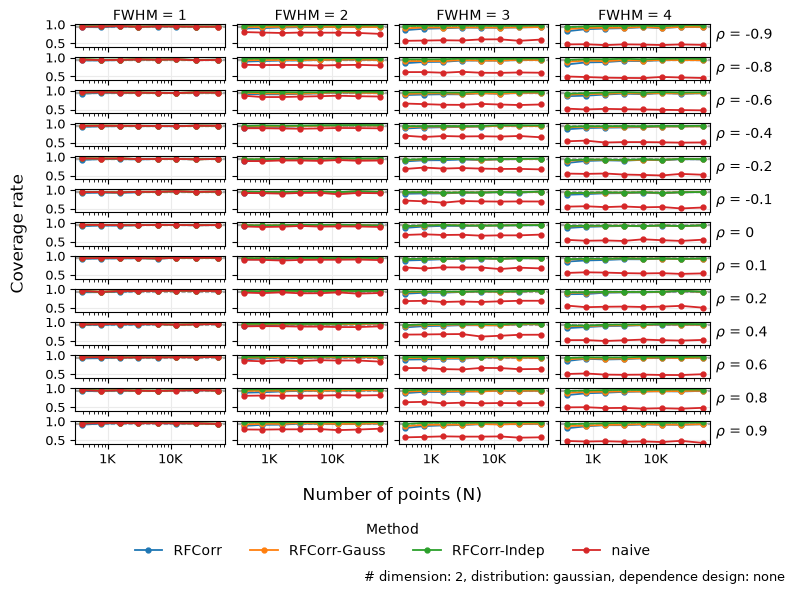

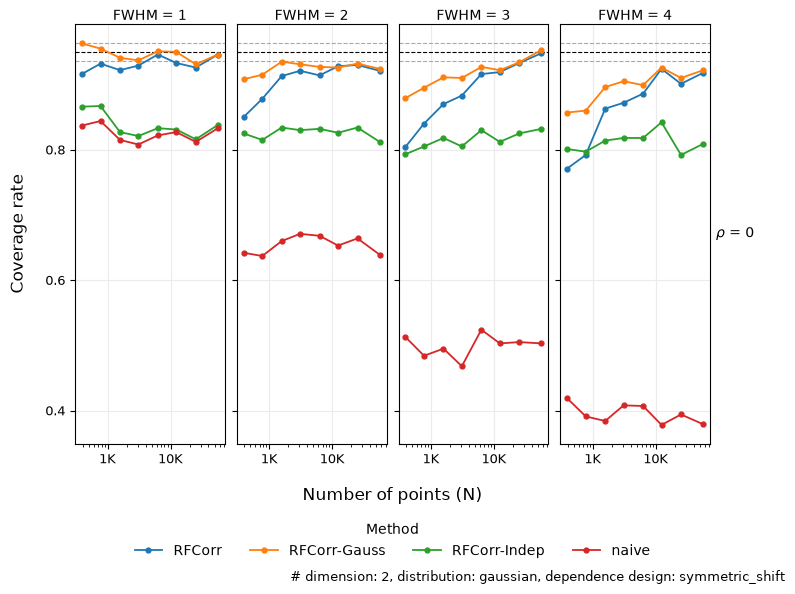

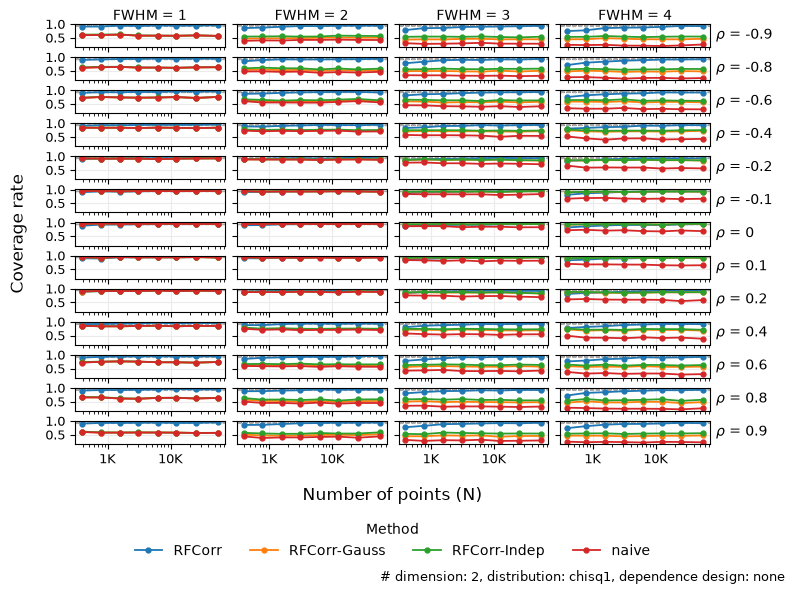

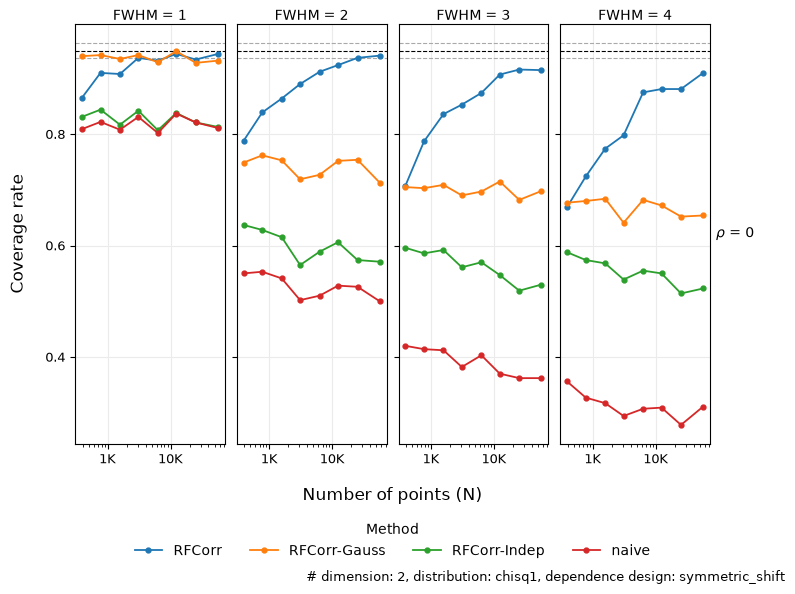

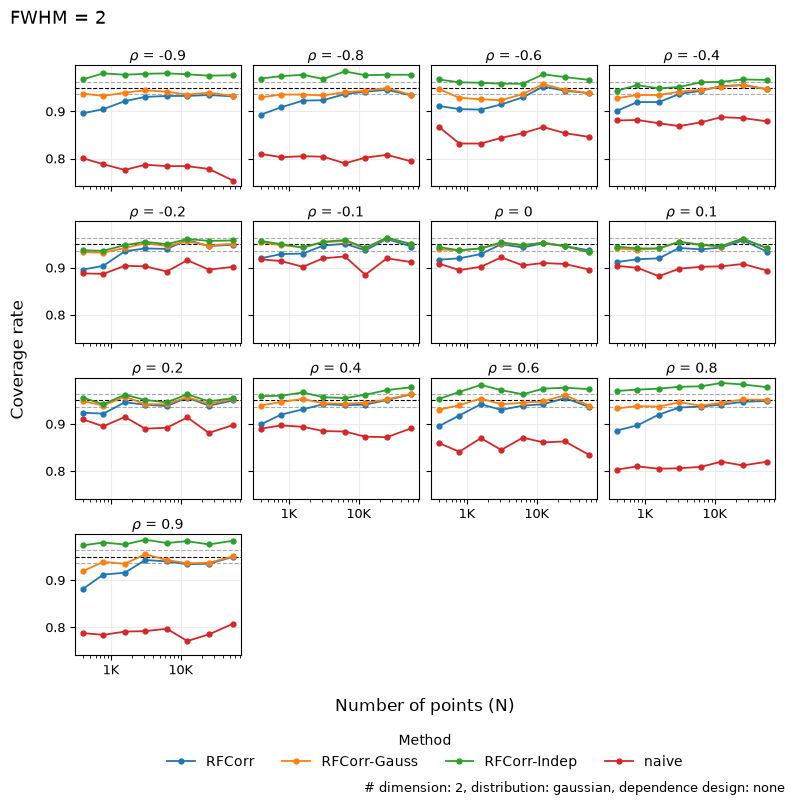

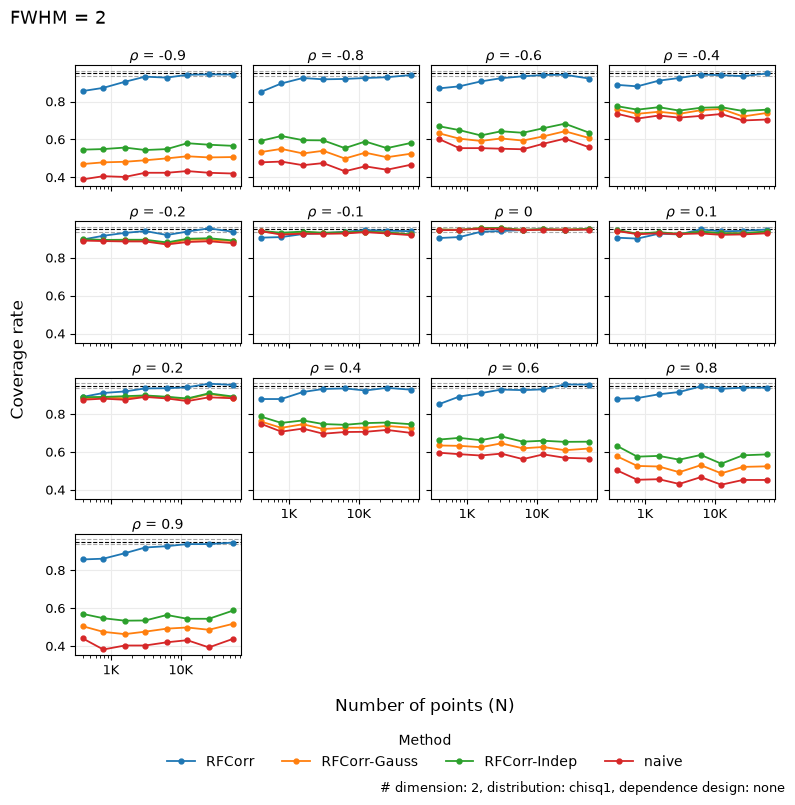

In [5]:
# coverage colored by method, fixed bandwidth rule, one figure per distribution and design
sim_all_plot = sim_all[sim_all["paper_rule"]]
# file-name tag for each design; no tag without a design, any other design is tagged by its name
dep_tags = {"none": "", "shift": "_shift", "symmetric_shift": "_symmetric"}


def dep_tag(dep):
    return dep_tags.get(dep, f"_{dep}")


dists = [d for d in ["gaussian", "chisq1"] if d in set(sim_all_plot["distribution"])]
for dist in dists:
    for dep in sim_all_plot["dep_model"].unique():
        # skip combinations with no rows (e.g. a design run only with Gaussian fields)
        if not ((sim_all_plot["distribution"] == dist) & (sim_all_plot["dep_model"] == dep)).any():
            continue
        fig = plot_by_method(sim_all_plot, distribution=dist, dep_model=dep, caption=True,
                             method_labels=labels_ci)
        save_and_show(fig, f"coverage_{sim_name}_by_method_{dist}{dep_tag(dep)}.jpg")

# coverage by rho for one FWHM: one panel per rho, in increasing order of rho. Only rows
# without a design, since the dependence designs are run with rho = 0 only
fwhm_fixed = 2
sim_rho_plot = sim_all_plot[(sim_all_plot["dep_model"] == "none")
                            & (sim_all_plot["fwhm"] == fwhm_fixed)]

for dist in [d for d in ["gaussian", "chisq1"] if d in set(sim_rho_plot["distribution"])]:
    fig = plot_by_method(sim_rho_plot, wrap="rho", ncol=4, distribution=dist, dep_model="none",
                         caption=True, method_labels=labels_ci, title=f"FWHM = {fwhm_fixed}",
                         figsize=(8, 8))
    save_and_show(fig, f"coverage_{sim_name}_by_rho_{dist}_fwhm{fwhm_fixed}.jpg")

## Type I error

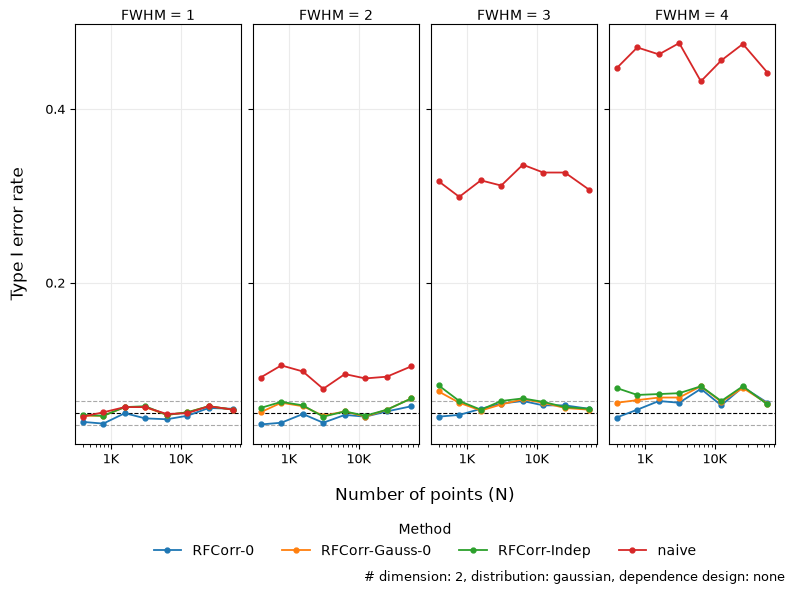

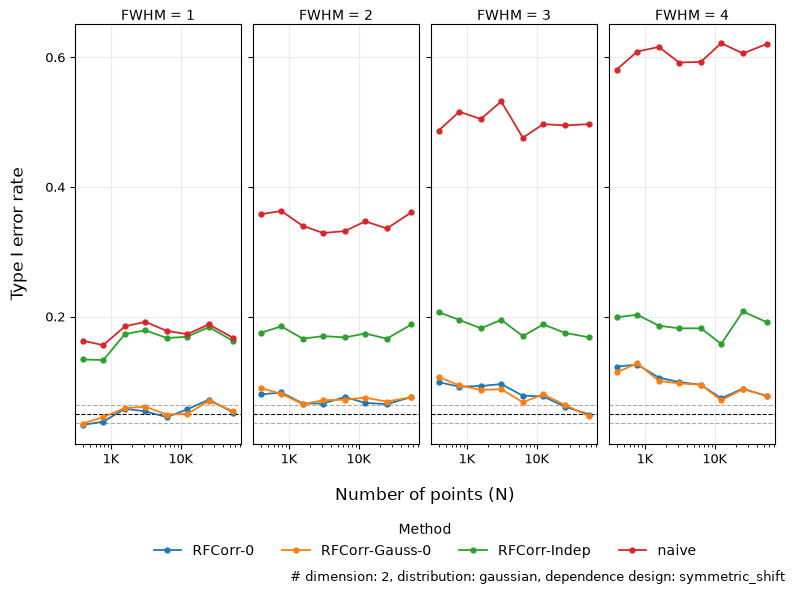

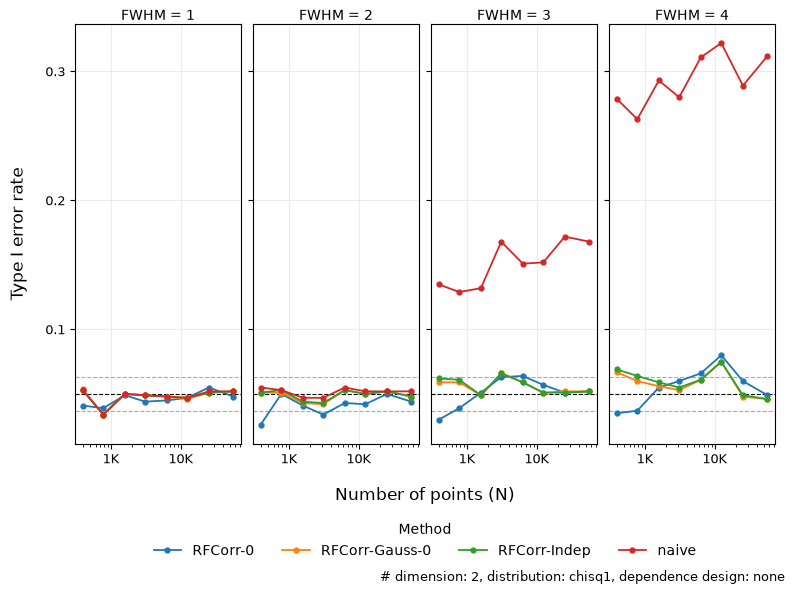

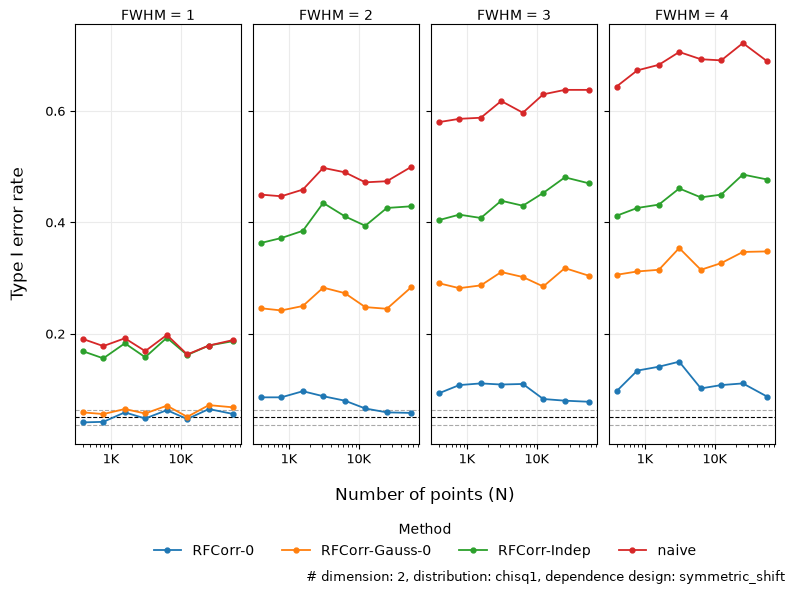

In [6]:
# Type I error rate colored by method: rho = 0, fixed bandwidth rule,
# one figure per distribution and dependence design present in the data
sim_all_plot = sim_all[sim_all["paper_rule"] & (sim_all["rho"] == 0)]
deps = sim_all_plot["dep_model"].unique()

for dist in [d for d in ["gaussian", "chisq1"] if d in set(sim_all_plot["distribution"])]:
    for dep in deps:
        if not ((sim_all_plot["distribution"] == dist) & (sim_all_plot["dep_model"] == dep)).any():
            continue
        fig = plot_by_method(sim_all_plot, rows=None, cols="fwhm", y="power", target=alpha,
                             ylab="Type I error rate", distribution=dist, dep_model=dep,
                             caption=True, method_labels=labels_test)
        save_and_show(fig, f"type1_error_{sim_name}_by_method_{dist}{dep_tag(dep)}.jpg")

## Figures for the paper

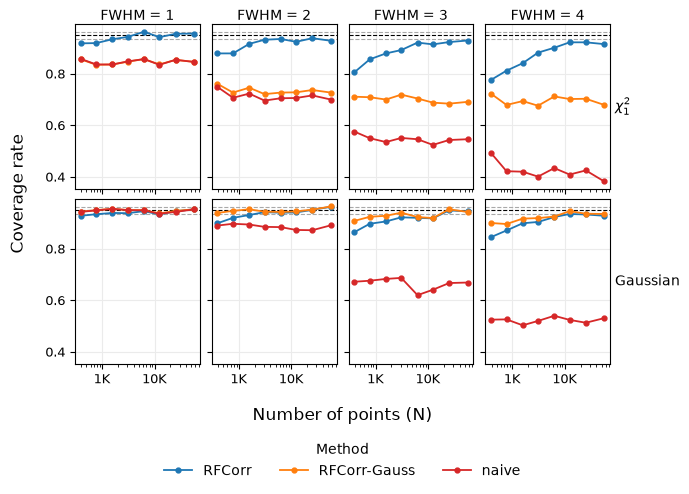

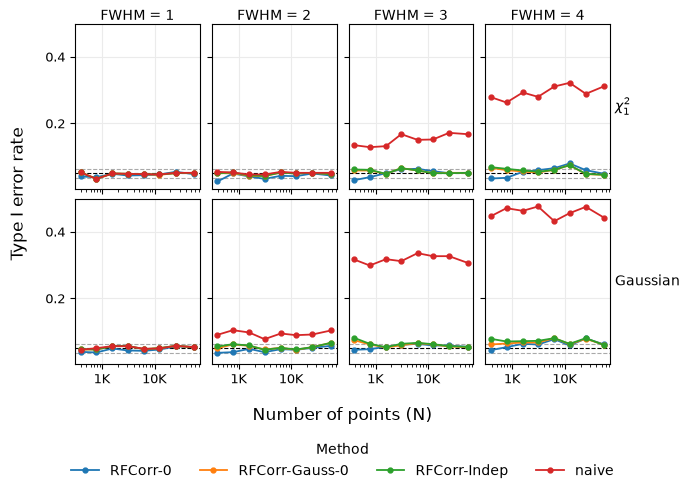

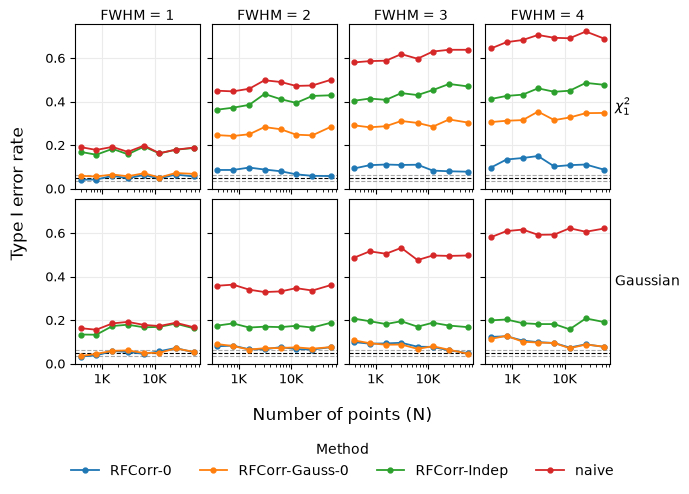

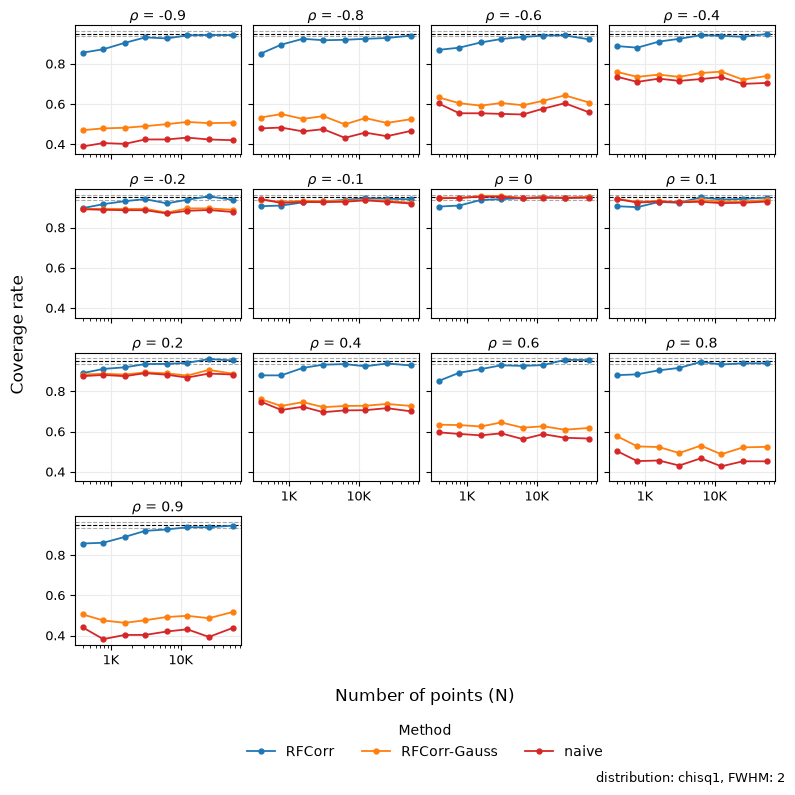

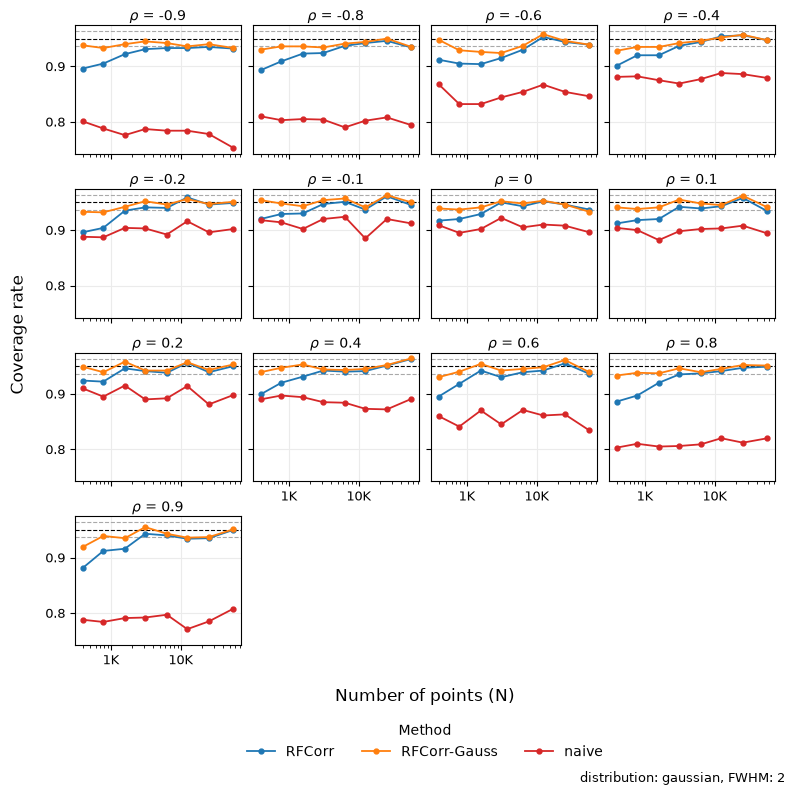

In [7]:
# coverage for one rho, both distributions, without RFCorr-Indep
data = sim_all[sim_all["paper_rule"] & (sim_all["rho"] == 0.4) & (sim_all["method"] != "indep")]
fig = plot_by_method(data, rows="distribution", cols="fwhm", dep_model="none",
                     method_labels=labels_ci, figsize=(7, 5))
save_and_show(fig, "Fig1_coverage.jpg", dpi=600)

# type I error, both distributions, independent fields (no dependence design)
data = sim_all[sim_all["paper_rule"] & (sim_all["rho"] == 0)]
fig = plot_by_method(data, rows="distribution", cols="fwhm", dep_model="none", y="power",
                     target=alpha, ylab="Type I error rate", method_labels=labels_test,
                     figsize=(7, 5))
save_and_show(fig, "Fig2_type1err.jpg", dpi=600)

# type I error under the symmetric shift design (rho = 0 but X and Y dependent)
fig = plot_by_method(data, rows="distribution", cols="fwhm", dep_model="symmetric_shift",
                     y="power", target=alpha, ylab="Type I error rate",
                     method_labels=labels_test, figsize=(7, 5))
save_and_show(fig, "Fig3_type1err_symmetric.jpg", dpi=600)

# supplementary: coverage by rho for one FWHM, without RFCorr-Indep; one panel per rho in
# increasing order, and a caption with only the distribution and FWHM.
# FigS1 for chi^2_1 fields, FigS2 for Gaussian fields
figS_fwhm = 2
figS_number = {"chisq1": 1, "gaussian": 2}
data = sim_all[sim_all["paper_rule"] & (sim_all["fwhm"] == figS_fwhm)
               & (sim_all["method"] != "indep")]
for dist, number in figS_number.items():
    fig = plot_by_method(data, wrap="rho", ncol=4, distribution=dist, dep_model="none",
                         method_labels=labels_ci,
                         caption=f"distribution: {dist}, FWHM: {figS_fwhm}", figsize=(8, 8))
    save_and_show(fig, f"FigS{number}_coverage_by_rho_{dist}_fwhm{figS_fwhm}.jpg", dpi=600)